# Python për Data Science – Sesioni 5
## Vizualizimi i të Dhënave me Matplotlib & Seaborn

📌 **Dataset:** `employees.csv`

### Qëllimi
- Të krijojmë grafikë të zakonshëm në Data Science
- Të zgjedhim grafikun sipas pyetjes
- Të lexojmë dhe interpretojmë rezultatet
- Të praktikojmë me ushtrime të thjeshta por të dobishme

> **Këshillë:** Pas çdo grafiku, pyet veten: *Çfarë po më tregon ky grafik?*


##  Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/employees.csv")
df.head()


,EmployeeID,Emri,Departamenti,Qyteti,Mosha,Paga,Data_Punesimit,Rating,Bonus
0,1001,Ilir,Sales,Pejë,46,494.0,2023-01-01,4.0,29
1,1002,Bora,Ops,Tiranë,54,1785.0,2023-01-08,3.0,192
2,1003,Kren,HR,Prizren,42,1750.0,2023-01-15,3.0,198
3,1004,Ina,HR,Tiranë,40,1261.0,2023-01-22,4.0,138
4,1005,Elio,Finance,Prishtinë,39,883.0,2023-01-29,1.0,48


## Përgatitje minimale e të dhënave (që grafikat të dalin mirë)

Ne do përdorim kolonat:
- `Paga` (ta kthejmë në numerike si `Paga`)
- `Data_Punesimit` (nëse ekziston, e kthejmë në datetime)
- kolona kategorike (`Departamenti`, `Qyteti`)

Kjo është vetëm përgatitje për vizualizim.


In [2]:
df2 = df.copy()

df2["Paga"] = pd.to_numeric(df2["Paga"], errors="coerce")

# Mbushim NaN për pagë vetëm që grafikat të mos prishen (për demonstrim)
df2["Paga"] = df2["Paga"].fillna(df2["Paga"].median())

# Data e punësimit (nëse kolona ekziston)
if "Data_Punesimit" in df2.columns:
    df2["Data_Punesimit"] = pd.to_datetime(df2["Data_Punesimit"], errors="coerce")


# Përdorimi i Matplotlib:
1. Më shumë kontroll mbi grafikun
2. I përshtatshëm për grafikë të personalizuar
3. I dobishëm kur vlerat janë tashmë të llogaritura


# Përdorimi i Seaborn:
1. Më pak kod
2. Grupim automatik i të dhënave
3. Pamje më të pastra(Default)
4. I përshtatshëm për eksplorimin e të dhënave

Seaborn vizaton grafikun, Matplotlib e menaxhon atë.

## Pyetja → Grafiku (rregull i artë)

- **Trend me kalimin e kohës** → Line plot
- **Krahasim kategorish** → Bar plot  
- **Sa raste ka çdo kategori** → Countplot  
- **Shpërndarje e një vlere numerike** → Histogram  
- **Krahasim shpërndarjes sipas grupeve** → Boxplot  
- **Lidhje mes dy variablave numerike** → Scatter plot  



## Line plot – Trend me kalimin e kohës

Le të bëjmë trend të pagës mesatare sipas vitit


In [3]:
df2["Viti"] = df2["Data_Punesimit"].dt.year
trend = df2.groupby("Viti")["Paga"].mean().reset_index()
trend


,Viti,Paga
0,2023,1340.192982
1,2024,1953.714286


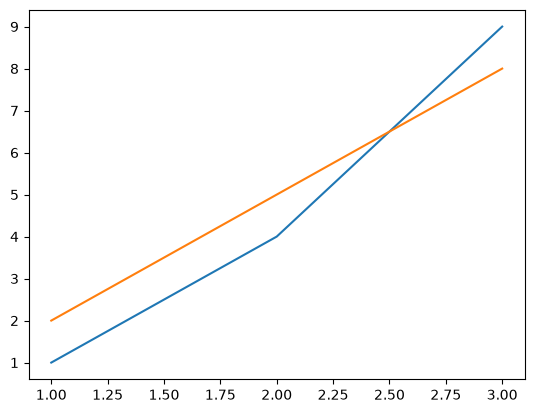

In [4]:
# plt.figure()
plt.plot([1, 2, 3], [1, 4, 9])

# plt.figure()
plt.plot([1, 2, 3], [2, 5, 8])

plt.show()

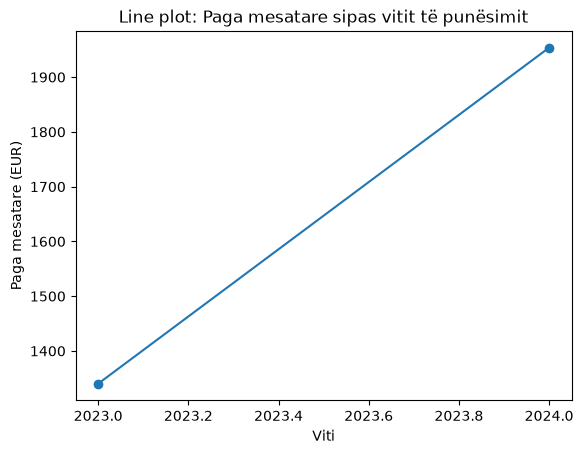

In [5]:
plt.figure()
plt.plot(trend.Viti, trend.Paga, marker="o")
plt.title("Line plot: Paga mesatare sipas vitit të punësimit")
plt.xlabel("Viti")
plt.ylabel("Paga mesatare (EUR)")
plt.show()


In [6]:
# else:
df_line = pd.DataFrame({
    "Viti": [2021, 2022, 2023, 2024, 2025],
    "Paga_Mesatare": [1100, 1150, 1200, 1300, 1350]
})
df_line


,Viti,Paga_Mesatare
0,2021,1100
1,2022,1150
2,2023,1200
3,2024,1300
4,2025,1350


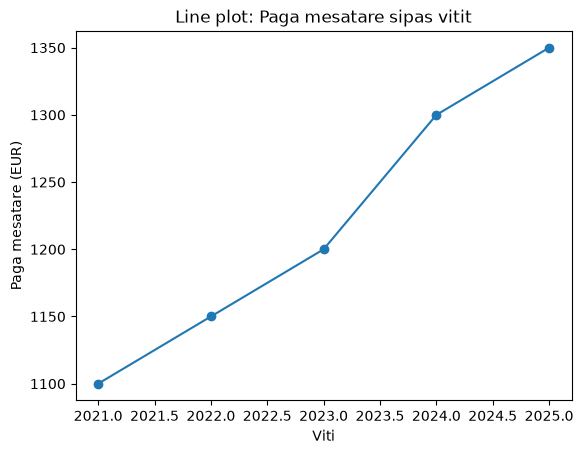

In [7]:
plt.figure()
plt.plot(df_line["Viti"], df_line["Paga_Mesatare"], marker="o")
plt.title("Line plot: Paga mesatare sipas vitit")
plt.xlabel("Viti")
plt.ylabel("Paga mesatare (EUR)")
plt.show()

## Bar plot – Krahasim i vlerave mes kategorive

**Pyetja:** Cili departament ka pagën mesatare më të lartë?


In [8]:
dept_mean = df2.groupby("Departamenti")["Paga"].mean().sort_values(ascending=False)
dept_mean = dept_mean.reset_index()
dept_mean


,Departamenti,Paga
0,Marketing,1587.909091
1,HR,1523.363636
2,Ops,1396.400000
3,Finance,1361.687500
4,IT,1309.200000
5,Sales,1101.888889


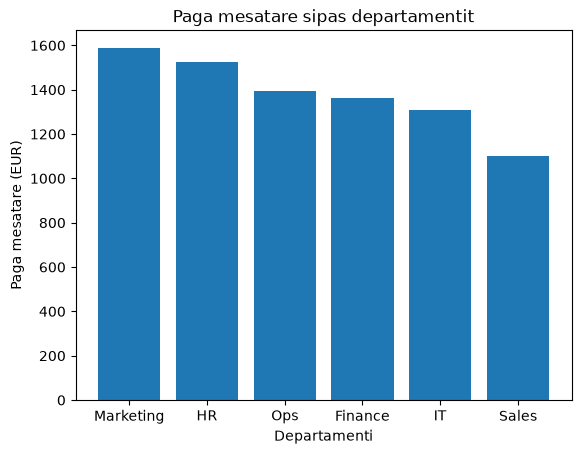

In [9]:
plt.figure() #gjithmone thirret ashtu qe python te hap nje grafik te ri (bosh), perndryshe i mbishkrun te gjithe grafiket ne nje
plt.bar(dept_mean.Departamenti, dept_mean.Paga)
plt.title("Paga mesatare sipas departamentit")
plt.xlabel("Departamenti")
plt.ylabel("Paga mesatare (EUR)")
plt.show()


Mund të përdorësh vetëm Seaborn kur:
1. nuk ke nevojë për tituj të personalizuar
2. nuk rrotullon etiketa
3. nuk shton layout, legend, grid
4. je në fazë eksplorimi të shpejtë

<Axes: xlabel='Departamenti', ylabel='Paga'>

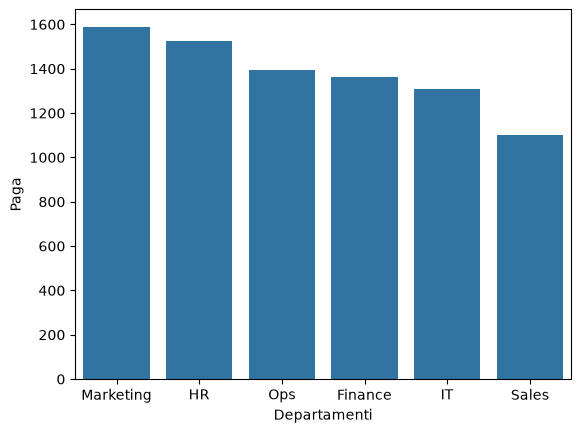

In [10]:

sns.barplot(data=dept_mean, x="Departamenti", y="Paga")

## Countplot – Sa raste ka çdo kategori

**Pyetja:** Sa punonjës ka në çdo qytet?


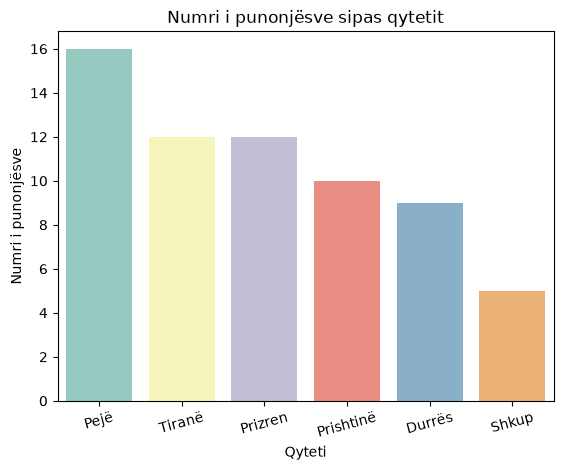

In [11]:
plt.figure()
sns.countplot(data=df2, x="Qyteti", hue="Qyteti", palette="Set3", legend=False)
plt.title("Numri i punonjësve sipas qytetit")
plt.xlabel("Qyteti")
plt.ylabel("Numri i punonjësve")
plt.xticks(rotation=15)
# Përdoret kur etiketat e boshtit X janë të gjata,
# për t’i bërë më të lexueshme dhe për të shmangur mbivendosjen.
plt.show()


## Histogram – Shpërndarja e një vlere numerike

**Pyetjet:** Si shpërndahen pagat? Ku është grumbullimi kryesor i vlerave?A ka “bisht” të gjatë (vlera ekstreme)?


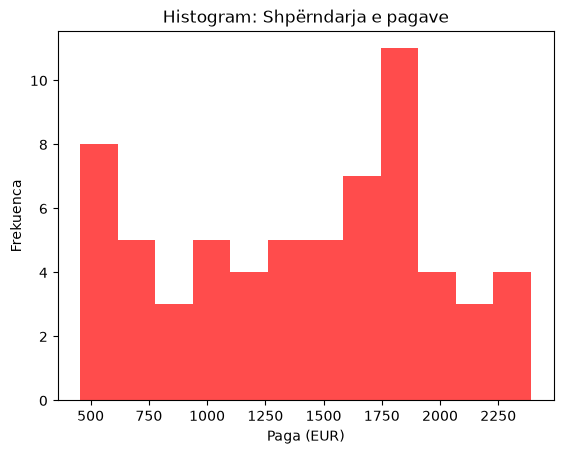

In [12]:
plt.figure()
plt.hist(df2["Paga"], bins=12, color="red", alpha=0.7)
plt.title("Histogram: Shpërndarja e pagave")
plt.xlabel("Paga (EUR)")
plt.ylabel("Frekuenca")
plt.show()


# color → bar color
# alpha → transparency (very useful!)

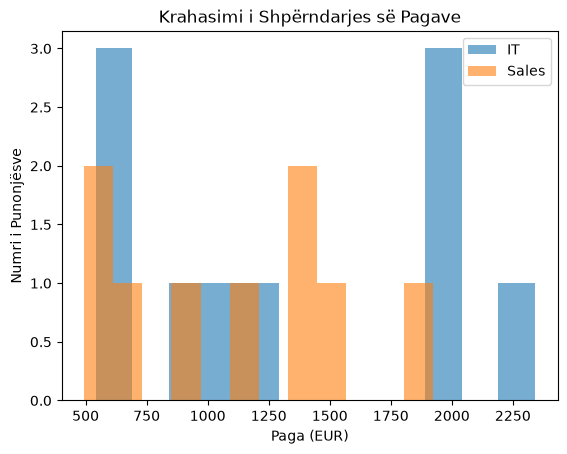

In [13]:
df_sales = df2[df2["Departamenti"] == "Sales"]
df_it = df2[df2["Departamenti"] == "IT"]

plt.figure()
plt.hist(df_it["Paga"], bins=12, alpha=0.6, label="IT")
plt.hist(df_sales["Paga"], bins=12, alpha=0.6, label="Sales")

plt.title("Krahasimi i Shpërndarjes së Pagave")
plt.xlabel("Paga (EUR)")
plt.ylabel("Numri i Punonjësve")
plt.legend()

plt.show()

In [14]:
# plt.hist?

## Boxplot – Variacioni dhe outliers sipas grupeve

**Pyetja:** A ka departamente me variacion më të madh të pagës?


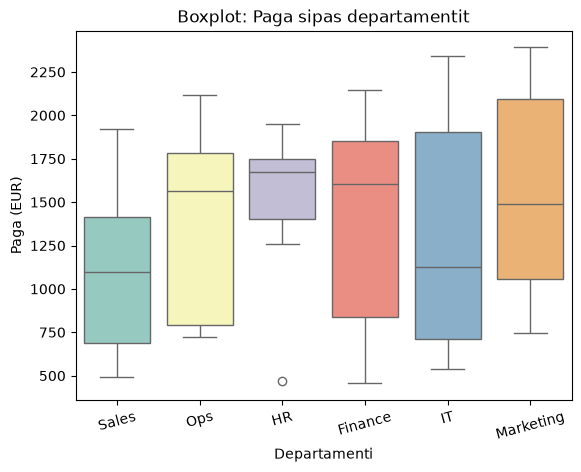

In [15]:
plt.figure()
sns.boxplot(data=df2, x="Departamenti", y="Paga", hue="Departamenti", palette="Set3", legend=False)
plt.title("Boxplot: Paga sipas departamentit")
plt.xlabel("Departamenti")
plt.ylabel("Paga (EUR)")
plt.xticks(rotation=15)
plt.show()


Në një Boxplot krahasojmë tre gjëra kryesore:
1. Medianën – kush ka pagë tipike më të lartë?
2. Lartësinë e kutisë – kush ka më shumë variacion në paga?
3. Vlerat ekstreme (outliers) – kush ka paga jo të zakonshme?

## Scatter plot – Lidhja mes dy variablave numerike

**Pyetja:** A ka lidhje midis moshës dhe pagës?


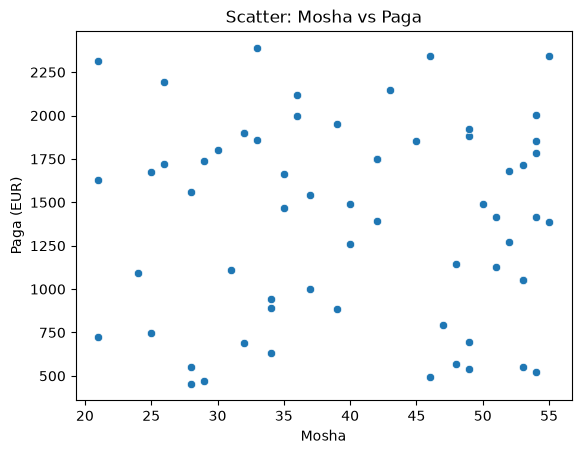

In [16]:
plt.figure()
sns.scatterplot(data=df2, x="Mosha", y="Paga")
plt.title("Scatter: Mosha vs Paga")
plt.xlabel("Mosha")
plt.ylabel("Paga (EUR)")
plt.show()


### Scatter me `hue`

Ngjyrosim pikat sipas qytetit për të parë dallime mes grupeve.


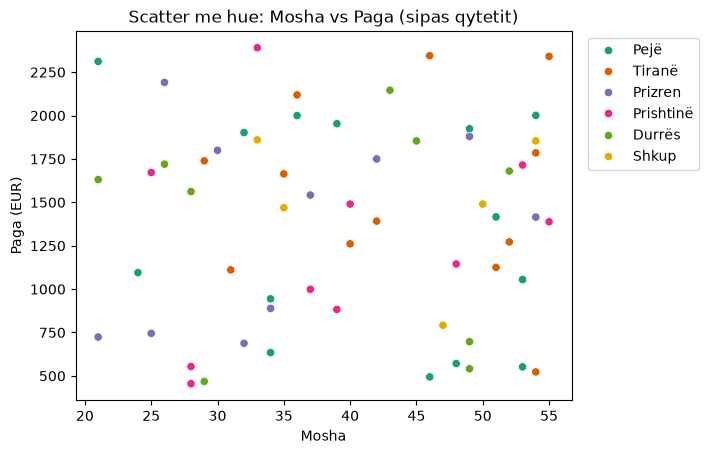

In [17]:
plt.figure()
sns.scatterplot(data=df2, x="Mosha", y="Paga", hue="Qyteti", palette="Dark2"
               )
plt.title("Scatter me hue: Mosha vs Paga (sipas qytetit)")
plt.xlabel("Mosha")
plt.ylabel("Paga (EUR)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


## Practice Time


## Ushtrimi 1 – “Kush fiton më shumë?” (Barplot)

**Kërkesa:**
1) Krijo një dataframe me emrin `dept_stats`, me pagën **mesatare** dhe **median** sipas `Departamenti`  
2) Vizato **bar plot** të pagës mesatare sipas departamentit  
2) Vizato **bar plot** të pagës mediane sipas departamentit  


## Ushtrimi 2 – “Sa kemi në çdo grup?” (Countplot + Hue)

**Kërkesa:**
1) Krijo `Paga_Level` me `np.where`: `"High"` nëse `Paga >= 1200`, ndryshe `"Normal"`  
2) Bëj **countplot** të `Departamenti`  
3) Bëj countplot të `Departamenti` me `hue="Paga_Level"`  


## Ushtrimi 3 – “A ka lidhje?” (Histogram + Boxplot)

**Kërkesa:**
1) Vizato **histogram** për kolonën `Bonus` për të parë shpërndarjen e përgjithshme të bonuseve
2) Bëj një **boxplot** të `Bonus` dhe `Paga_Level`, të krahasojmë bonuset e punonjësve me paga të larta dhe normale


### Interpretimi : 
Histogrami tregon se shumica e bonuseve janë të përqendruara në vlera më të ulëta, ndërsa disa bonuse të larta krijojnë shpërndarje të pabarabartë.
Boxplot-i tregon se punonjësit me paga më të larta kanë zakonisht bonus median më të lartë dhe variacion më të madh, duke sugjeruar që niveli i pagës lidhet edhe me shpërblimin shtesë.

---
## Mbyllje

Sot mësuam të zgjedhim grafikun sipas pyetjes dhe të interpretojmë rezultatet vizuale.
